Step 1 — Import Libraries

In [5]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Train-test split
from sklearn.model_selection import train_test_split

# Encoding and scaling
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

Step 1 — Data Loading

In [6]:
# Load the Telco Customer Churn dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape

In [7]:
df.shape

(7043, 21)

Dataset information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Column names

In [9]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

Check duplicate values

In [10]:
df.duplicated().sum()

np.int64(0)

Check Churn distribution

In [11]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


Percentage:

In [12]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


**Step 2 – Data Cleaning & Preprocessing.**

2.1 TotalCharges numeric

In [13]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

2.2 Missing values check

In [14]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


2.3 Missing rows remove

In [15]:
df = df.dropna()

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (7032, 21)


2.4 CustomerID remove

In [16]:
df = df.drop("customerID", axis=1)

2.5 Churn- 0/1

In [17]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

Check:

In [18]:
df["Churn"].value_counts()

,count
Churn,
0,5163
1,1869


2.6 Final dataset check

In [19]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

**Step 3 – Categorical Encoding.**

3.1 Separate input and target

In [21]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

3.2 Convert categorical columns using One-Hot Encoding

In [22]:
# One-hot encode categorical variables

X = pd.get_dummies(X, drop_first=True)

3.3 Check the encoded data

In [23]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


3.4 Check number of features

In [24]:
print("Number of features:", X.shape[1])

Number of features: 30


3.5 Convert boolean values to integers

In [25]:
X = X.astype(int)

3.6 Check target

In [26]:
print("Target values:")
print(y.value_counts())

Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


**Step 4 – Train-Test Split + Feature Scaling.**

4.1 Split the dataset

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5625, 30)
Testing data: (1407, 30)


4.2 Feature Scaling

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

4.3 Check scaled data

In [29]:
print("Training data after scaling:")
print(X_train_scaled[:5])

Training data after scaling:
[[-0.43931886  1.3218163   0.97874047  1.65977755  0.99627361  1.02831173
   1.5291432   0.32754155 -0.32754155  1.16554303  1.12490211 -0.52296156
  -0.52296156  1.57642955 -0.52296156  1.36157309 -0.52296156  1.37605179
  -0.52296156  1.54681665 -0.52296156 -0.79787323 -0.52296156 -0.79996356
  -0.51578723  1.77260282 -1.21302973  1.90515869 -0.71617747 -0.5394682 ]
 [-0.43931886 -0.26741023 -0.98094299 -0.56226653  0.99627361 -0.97246775
  -0.65396099 -3.05304781  3.05304781 -0.85796918 -0.88896624 -0.52296156
  -0.52296156 -0.63434487 -0.52296156 -0.7344446  -0.52296156  1.37605179
  -0.52296156  1.54681665 -0.52296156 -0.79787323 -0.52296156 -0.79996356
  -0.51578723 -0.56414217 -1.21302973 -0.52489066  1.39630196 -0.5394682 ]
 [-0.43931886  1.4440645   0.84588057  1.7560251  -1.00374033  1.02831173
  -0.65396099  0.32754155 -0.32754155  1.16554303  1.12490211 -0.52296156
  -0.52296156 -0.63434487 -0.52296156  1.36157309 -0.52296156  1.37605179
  -0.52

4.4 Check dimensions

In [30]:
print("X_train:", X_train_scaled.shape)
print("X_test:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 30)
X_test: (1407, 30)
y_train: (5625,)
y_test: (1407,)


**Step 5 – ANN Model Creation & Compilation. **

5.1 Import ANN layers

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

5.2 Create ANN model

In [32]:
ann_model = Sequential([

    # Input + First Hidden Layer
    Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),

    # Dropout
    Dropout(0.3),

    # Second Hidden Layer
    Dense(32, activation="relu"),

    # Dropout
    Dropout(0.2),

    # Output Layer
    Dense(1, activation="sigmoid")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5.3 Display model architecture

In [33]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

5.4 Compile the ANN

In [34]:
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

**Step 6 – ANN Model Training.**

6.1 Train the ANN

In [35]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7416 - loss: 0.5057 - val_accuracy: 0.7911 - val_loss: 0.4223
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7887 - loss: 0.4459 - val_accuracy: 0.7956 - val_loss: 0.4127
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7927 - loss: 0.4360 - val_accuracy: 0.7902 - val_loss: 0.4097
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7984 - loss: 0.4322 - val_accuracy: 0.7911 - val_loss: 0.4087
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8009 - loss: 0.4295 - val_accuracy: 0.8044 - val_loss: 0.4091
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - loss: 0.4261 - val_accuracy: 0.8018 - val_loss: 0.4086
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7978 - loss: 0.4267 - val_accuracy: 0.8018 - val_loss: 0.4075
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8013 - loss: 0.4224 - val_accuracy: 0.

6.2 Plot Training & Validation Accuracy

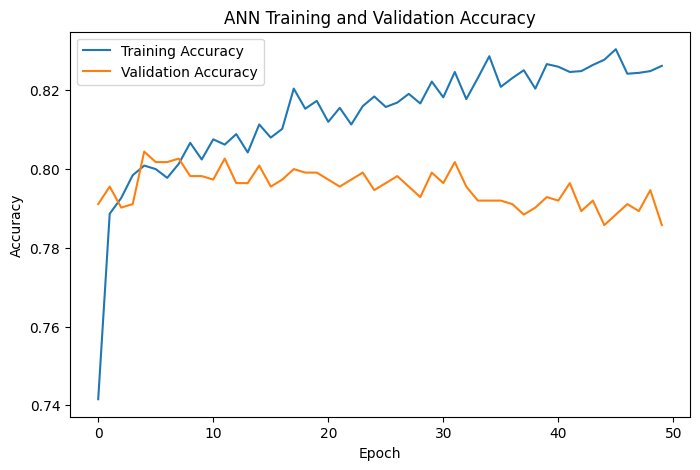

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

6.3 Plot Training & Validation Loss

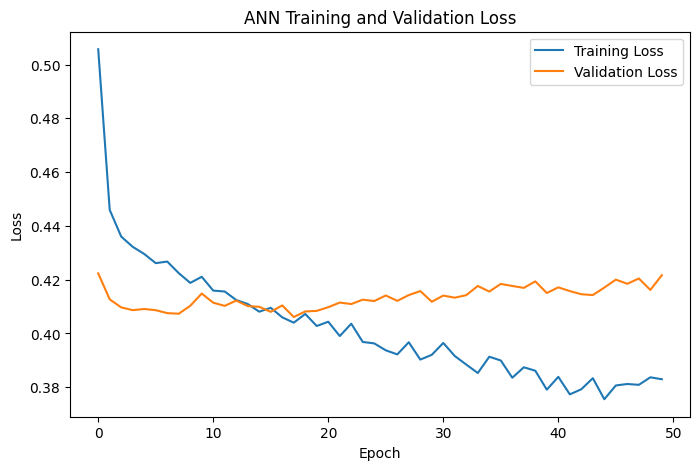

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

**Step 7 – ANN Prediction & Evaluation.**

7.1 Predict on test data

In [38]:
y_prob = ann_model.predict(X_test_scaled)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


7.2 Convert probability into class

In [39]:
y_pred = (y_prob >= 0.5).astype(int)

7.3 Calculate Accuracy

In [40]:
accuracy = accuracy_score(y_test, y_pred)

print("ANN Accuracy:", accuracy)
print("ANN Accuracy (%):", accuracy * 100)

ANN Accuracy: 0.7746979388770433
ANN Accuracy (%): 77.46979388770433


7.4 Classification Report

In [41]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1033
           1       0.60      0.48      0.53       374

    accuracy                           0.77      1407
   macro avg       0.71      0.68      0.69      1407
weighted avg       0.76      0.77      0.77      1407



7.5 Confusion Matrix

In [42]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[912 121]
 [196 178]]


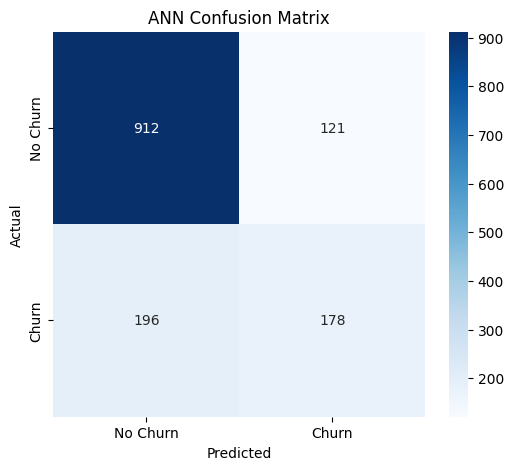

In [43]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")

plt.show()

7.6 ROC-AUC

In [44]:
roc_auc = roc_auc_score(y_test, y_prob)

print("ANN ROC-AUC Score:", roc_auc)

ANN ROC-AUC Score: 0.8260543766921536


7.7 ROC Curve

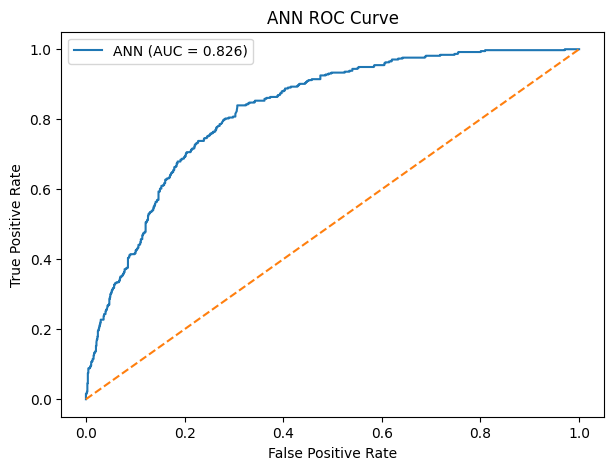

In [45]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ANN (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ANN ROC Curve")
plt.legend()

plt.show()

Step 8 – Churn Probability + Model Save.

8.1 Churn probability

In [46]:
churn_probability = y_prob.flatten() * 100

print("First 10 customer churn probabilities:")
print(churn_probability[:10])

First 10 customer churn probabilities:
[ 0.73599994 70.52349     0.5769716  27.618732   14.829664   43.63663
  4.2095923  25.295729   79.06621     0.72699094]


8.2 Prediction result table

In [47]:
results = pd.DataFrame({
    "Actual Churn": y_test.values,
    "Predicted Churn": y_pred.flatten(),
    "Churn Probability (%)": churn_probability
})

results.head(10)

,Actual Churn,Predicted Churn,Churn Probability (%)
0,0,0,0.736000
1,0,1,70.523491
2,0,0,0.576972
3,1,0,27.618732
4,0,0,14.829664
5,1,0,43.636631
6,0,0,4.209592
7,0,0,25.295729
8,1,1,79.066208
9,0,0,0.726991


8.3 High-risk customers

In [48]:
high_risk = results[results["Churn Probability (%)"] >= 50]

print("High-risk customers:", len(high_risk))

high_risk.head(10)

High-risk customers: 299


,Actual Churn,Predicted Churn,Churn Probability (%)
1,0,1,70.523491
8,1,1,79.066208
10,0,1,63.693302
15,1,1,85.830521
16,1,1,75.008766
17,1,1,58.366997
22,0,1,57.761635
31,1,1,78.546082
34,1,1,67.450180
53,1,1,66.860023


8.4 Save the ANN model

In [49]:
ann_model.save("customer_churn_ann.keras")

print("ANN model saved successfully!")

ANN model saved successfully!


8.5 Save the scaler

In [50]:
import joblib

joblib.dump(scaler, "churn_scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [51]:
# Create a sample new customer

new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [12],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["Yes"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [80.5],
    "TotalCharges": [966.0]
})

new_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,12,Yes,No,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,80.5,966.0


In [52]:
# Apply one-hot encoding

new_customer_encoded = pd.get_dummies(
    new_customer,
    drop_first=True
)

In [53]:
# Match the training columns

new_customer_encoded = new_customer_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

In [54]:
# Scale the new customer data

new_customer_scaled = scaler.transform(new_customer_encoded)

In [55]:
# Predict churn probability

prediction_probability = ann_model.predict(new_customer_scaled)[0][0]

print("Churn Probability:", prediction_probability * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Churn Probability: 42.888084 %


In [56]:
if prediction_probability >= 0.5:
    print("Prediction: Customer is likely to CHURN")
else:
    print("Prediction: Customer is likely to STAY")

Prediction: Customer is likely to STAY


In [59]:
import os

project_path = "/content/drive/MyDrive/Customer-Churn-Prediction-ANN"

os.makedirs(project_path, exist_ok=True)

print("Project folder ready:", project_path)

Project folder ready: /content/drive/MyDrive/Customer-Churn-Prediction-ANN


In [60]:
import os
import joblib

ann_model.save(
    os.path.join(project_path, "customer_churn_ann.keras")
)

joblib.dump(
    scaler,
    os.path.join(project_path, "churn_scaler.pkl")
)

print("ANN model and scaler saved successfully!")

ANN model and scaler saved successfully!


In [61]:
print(os.listdir(project_path))

['churn_scaler.pkl', 'customer_churn_ann.keras']
